# AI-ML Recruitment 2026 — Task 2
## Handwritten Digit Classification using a Neural Network

**Candidate:** Tharun  
**Program:** CSE AIML  
**Year:** Second Year  

### Objective
Build and evaluate a simple neural network to classify handwritten digits from 0 to 9 using the MNIST dataset.

> **Note:** This notebook follows the second-year recruitment task requirements. Run all cells from top to bottom before submission.


## 1. Dataset Understanding

MNIST is a handwritten digit dataset containing grayscale images of digits from **0 to 9**.

For this project:
- Each image is **28 × 28 pixels**.
- There are **10 classes**, representing digits 0 through 9.
- Each label identifies the digit shown in the corresponding image.


In [ ]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.20.0


## 2. Load the MNIST Dataset

In [ ]:
# Load MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)
print("Number of classes:", len(np.unique(y_train)))


Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)
Number of classes: 10


## 3. Explore the Dataset

The images are grayscale images. Pixel values originally range from 0 to 255.

The label is the actual digit represented by the image.


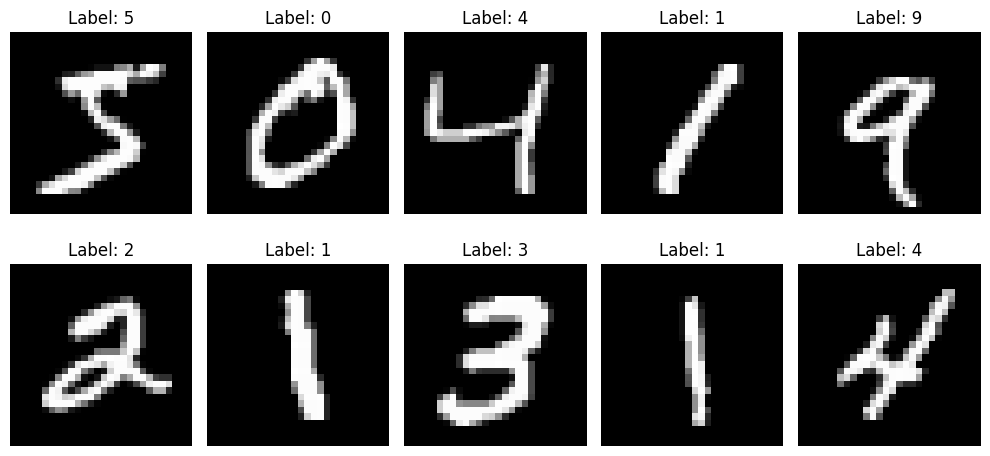

In [ ]:
# Display sample images
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# Inspect pixel values
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())


Minimum pixel value: 0
Maximum pixel value: 255


## 4. Data Preprocessing

### Normalization
Pixel values are divided by 255 so that they are scaled from approximately **0 to 1**. This makes the input values easier for the neural network to process.

### Flattening
Each 28 × 28 image will be flattened into a vector of **784 values** by the first layer of the model.


In [ ]:
# Normalize pixel values
x_train_norm = x_train.astype("float32") / 255.0
x_test_norm = x_test.astype("float32") / 255.0

print("Normalized minimum:", x_train_norm.min())
print("Normalized maximum:", x_train_norm.max())


Normalized minimum: 0.0
Normalized maximum: 1.0


## 5. Build the Original Neural Network

Architecture:

**Input (28×28) → Flatten → Dense hidden layer with ReLU → Dense output layer with Softmax**

- **ReLU** is used in the hidden layer.
- **Softmax** is used in the output layer because the problem has 10 possible classes.


In [ ]:
# Build the original model
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Compile the Model

We use:
- **Adam** optimizer to update model parameters.
- **Sparse categorical crossentropy** as the loss because labels are integer class IDs.
- **Accuracy** as the main metric.


In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


## 7. Train the Original Model

In [ ]:
history = model.fit(
    x_train_norm,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)


Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8968 - loss: 0.3766 - val_accuracy: 0.9487 - val_loss: 0.1875
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9490 - loss: 0.1772 - val_accuracy: 0.9647 - val_loss: 0.1259
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9627 - loss: 0.1282 - val_accuracy: 0.9690 - val_loss: 0.1062
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9713 - loss: 0.0982 - val_accuracy: 0.9733 - val_loss: 0.0967
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9774 - loss: 0.0806 - val_accuracy: 0.9742 - val_loss: 0.0918
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9809 - loss: 0.0666 - val_accuracy: 0.9750 - val_loss: 0.0850
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9842 - loss: 0.0555 - val_accuracy: 0.9755 - val_loss: 0.0830
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9863 - loss: 0.0477 - val_accuracy: 0.

## 8. Training and Validation Curves

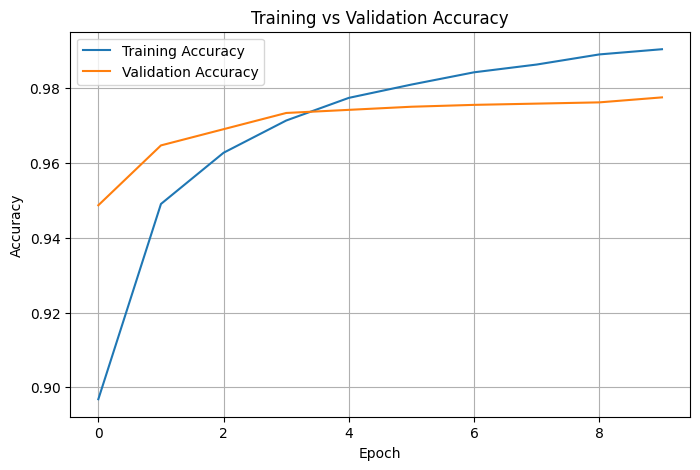

In [ ]:
# Accuracy curve
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


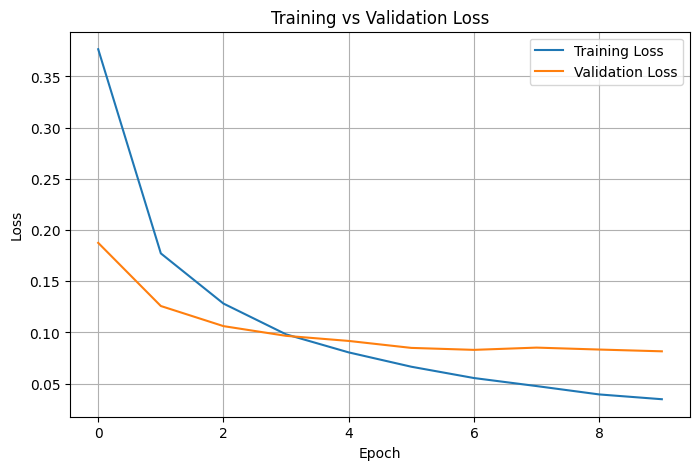

In [ ]:
# Loss curve
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


## 9. Evaluate the Original Model

In [ ]:
test_loss, test_accuracy = model.evaluate(x_test_norm, y_test, verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")


Test Loss: 0.0828
Test Accuracy: 0.9756
Test Accuracy (%): 97.56%


## 10. Confusion Matrix

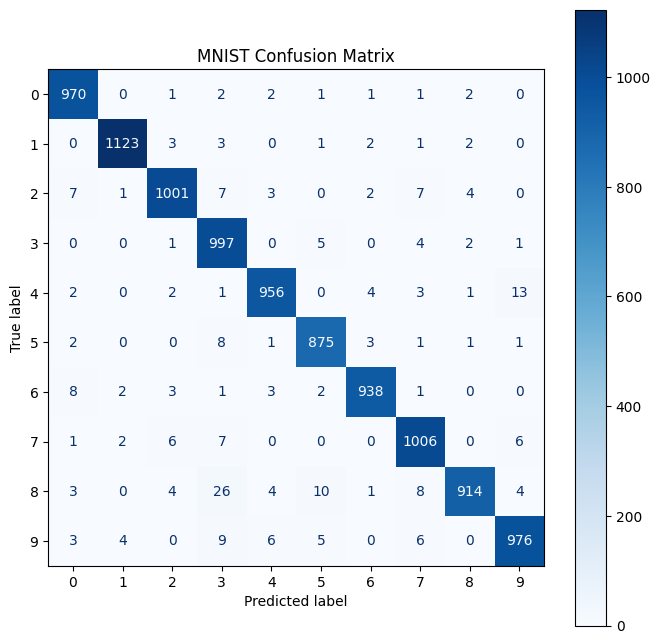

In [ ]:
# Generate predictions
y_prob = model.predict(x_test_norm, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("MNIST Confusion Matrix")
plt.show()


In [ ]:
# Additional classification metrics
print(classification_report(y_test, y_pred, digits=4))


              precision    recall  f1-score   support

           0     0.9739    0.9898    0.9818       980
           1     0.9920    0.9894    0.9907      1135
           2     0.9804    0.9700    0.9752      1032
           3     0.9397    0.9871    0.9628      1010
           4     0.9805    0.9735    0.9770       982
           5     0.9733    0.9809    0.9771       892
           6     0.9863    0.9791    0.9827       958
           7     0.9692    0.9786    0.9739      1028
           8     0.9870    0.9384    0.9621       974
           9     0.9750    0.9673    0.9711      1009

    accuracy                         0.9756     10000
   macro avg     0.9757    0.9754    0.9754     10000
weighted avg     0.9759    0.9756    0.9756     10000



## 11. Inspect Some Predictions

The following section displays sample test images together with the model's predicted digit and actual digit.


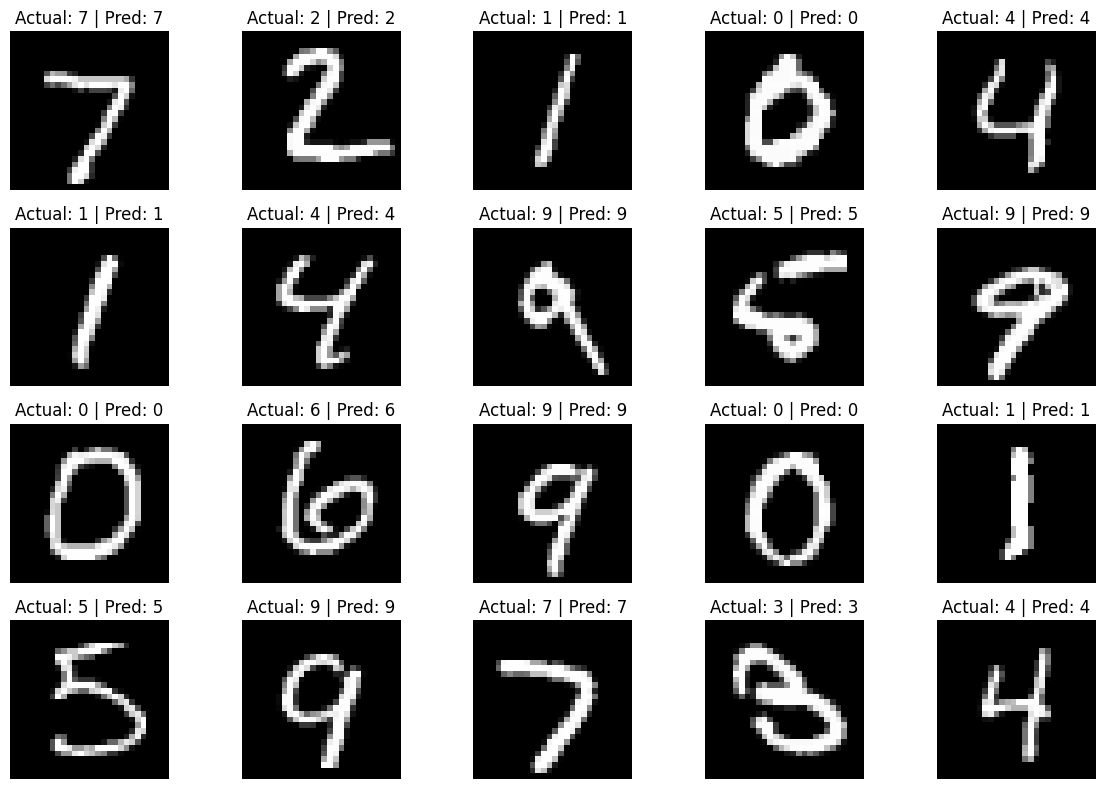

In [ ]:
# Show sample predictions
plt.figure(figsize=(12, 8))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"Actual: {y_test[i]} | Pred: {y_pred[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


## 12. Experiment — Increase the Number of Hidden Neurons

The recruitment task requires at least one experiment.

### Original model
- One hidden layer
- 128 neurons
- ReLU activation

### Modified model
- One hidden layer
- 256 neurons
- ReLU activation

Only the number of hidden neurons is changed so that the effect of this change can be compared.


In [ ]:
# Build the modified model
modified_model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax")
])

modified_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

modified_model.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_5 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,530 (795.04 KB)

 Trainable params: 203,530 (795.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train modified model
modified_history = modified_model.fit(
    x_train_norm,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)


Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9086 - loss: 0.3279 - val_accuracy: 0.9618 - val_loss: 0.1438
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9596 - loss: 0.1414 - val_accuracy: 0.9723 - val_loss: 0.1039
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9732 - loss: 0.0946 - val_accuracy: 0.9733 - val_loss: 0.0950
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9794 - loss: 0.0707 - val_accuracy: 0.9782 - val_loss: 0.0770
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9841 - loss: 0.0557 - val_accuracy: 0.9763 - val_loss: 0.0744
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9874 - loss: 0.0432 - val_accuracy: 0.9792 - val_loss: 0.0697
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9904 - loss: 0.0342 - val_accuracy: 0.9790 - val_loss: 0.0698
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9926 - loss: 0.0277 - val_accuracy: 0.

In [ ]:
# Evaluate modified model
modified_test_loss, modified_test_accuracy = modified_model.evaluate(
    x_test_norm, y_test, verbose=0
)

print(f"Modified Test Loss: {modified_test_loss:.4f}")
print(f"Modified Test Accuracy: {modified_test_accuracy:.4f}")
print(f"Modified Test Accuracy (%): {modified_test_accuracy * 100:.2f}%")


Modified Test Loss: 0.0665
Modified Test Accuracy: 0.9795
Modified Test Accuracy (%): 97.95%


## 13. Compare Original and Modified Models

In [ ]:
# Compare models using actual results
comparison = {
    "Original (128 neurons)": test_accuracy,
    "Modified (256 neurons)": modified_test_accuracy
}

for name, acc in comparison.items():
    print(f"{name}: {acc * 100:.2f}%")

print("\nExperiment interpretation:")
if modified_test_accuracy > test_accuracy:
    print("The modified model achieved higher test accuracy than the original model.")
elif modified_test_accuracy < test_accuracy:
    print("The modified model achieved lower test accuracy than the original model.")
else:
    print("Both models achieved the same test accuracy.")

print("The change tested was the number of neurons in the hidden layer.")


Original (128 neurons): 97.56%
Modified (256 neurons): 97.95%

Experiment interpretation:
The modified model achieved higher test accuracy than the original model.
The change tested was the number of neurons in the hidden layer.


## 14. Key Findings

After running the notebook, replace/add details below using the actual output:

1. MNIST contains grayscale handwritten digit images belonging to 10 classes (0–9).
2. The input images are 28 × 28 pixels and were normalized before training.
3. The neural network uses ReLU in the hidden layer and Softmax in the output layer.
4. The original model achieved a test accuracy of 97.56%.
5. The confusion matrix shows which digit classes are classified correctly and which classes are confused.
6. Increasing the hidden-layer size from 128 to 256 neurons increased the test accuracy from 97.56% to 97.95%.


## 15. Limitations

1. This is a simple fully connected neural network and does not explicitly exploit the spatial structure of images like a convolutional neural network does.
2. Model performance depends on architecture, hyperparameters, and training settings.
3. Accuracy alone does not describe every type of classification error; the confusion matrix and additional metrics provide more information.


## 16. Possible Improvement

A possible next step would be to build a Convolutional Neural Network (CNN), which is designed to work effectively with image data. Other possible improvements include systematic hyperparameter tuning and regularization.


## 17. Conclusion

A neural network was built to classify handwritten MNIST digits from 0 to 9. The project covered dataset understanding, normalization, neural-network construction, ReLU and Softmax activation functions, model training, evaluation, confusion-matrix analysis, and an experiment involving the number of hidden neurons.

**Before submission:** use `Runtime → Run all`, verify that every cell executes successfully, and update the README with the actual results produced by the notebook.
